## Testing how well the models fit
Could also be used to change e.g. size of network, but now worked on a brief proof of concept to train all models (in parallel) and compare them.




In [ ]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from halcyon.Simulators.GNWSimRunner import GNWSimRunner
from halcyon.Models.PhoenixModels import PhoenixOnlyAddLayers, PhoenixAddAndProdLayers
from halcyon.Models.CellBox import CellBox

# import torch.multiprocessing as mp
import multiprocessing as mp

from halcyon.Trainer import TrainingJob, run_training_job

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import logging

import torch
import numpy as np
import random

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 


logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

## Data generation

In [2]:
# nr_genes_list = [32, 64, 128]
nr_genes_list = [100]
# nr_modules_list = [16, 5, 10]
nr_modules_list = [20]
sparsity_list = [0.05]

sim_outputs = []
for nr_genes in nr_genes_list: 
    for nr_modules in nr_modules_list: 
        for sparsity in sparsity_list: 
            gnw_sim = GNWSimRunner(
                settings_path=Path("../setting_files/gnw_testing_runs_settings.txt"),
            )
            generated_data_path = Path("../data/fitting_on_multiple_sim_settings") / f"genes_{nr_genes}_modules_{nr_modules}_sparsity_{sparsity}"
            generated_data_path.mkdir(parents=True, exist_ok=True)
            network_name = 'my_network'
            sim_result = gnw_sim.run_simulation(
                n_genes=nr_genes,
                sparsity=sparsity,
                num_modules=nr_modules,
                network_name=network_name,
                output_path=generated_data_path,
            )
            sim_outputs.append(sim_result) 
sim_outputs

2025-10-22 17:11:15,401 - INFO - Generating network
Loading specified settings: ../setting_files/gnw_testing_runs_settings.txt
Done
Start network creation of type MODULAR_SCALEFREE
Setting dynamical model for my_network

Random initialization of my_network
my_network: Node_0: (Node_76*Node_10~Node_0~Node_78) + (Node_32*Node_11~Node_12~Node_19) + ~(Node_14*Node_2~Node_25) + ~(Node_30)
my_network: Node_1: ~(Node_54*Node_41*Node_29*Node_1) + ~(Node_11*Node_0) + (Node_15~Node_8)
my_network: Node_2: ~(Node_59*Node_31~Node_24) + (Node_93*Node_12*Node_7~Node_0~Node_2) + (Node_22) + ~(Node_20*Node_5)
my_network: Node_3: ~(Node_10*Node_51*Node_12) + ~(Node_23*Node_26~Node_34) + (Node_43*Node_22~Node_3) + ~(Node_6)
my_network: Node_4: ~(Node_8*Node_9~Node_11) + ~(Node_53) + ~(Node_71) + (Node_4~Node_0)
my_network: Node_5: (Node_9*Node_11) + ~(Node_8*Node_6*Node_65~Node_51) + (Node_5) + (Node_37~Node_23) + ~(Node_34)
my_network: Node_6: (Node_24*Node_25~Node_47) + ~(Node_11*Node_44*Node_22) + (No

[SimulationResult(data_path=PosixPath('/lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_100_modules_20_sparsity_0.05'), network_name='my_network', nr_genes=100, nr_modules=20, sparsity=0.05, keep_self_interactions=True)]

## Model fitting

In [3]:
# only fitting to one simulation
sim_result = sim_outputs[0]

In [7]:
devices = ["cuda:0", "cuda:1"]
# hidden_sizes = [8, 16]
hidden_sizes = [10, 20, 30]

train_jobs: list[TrainingJob] = []
train_steps = 1000

for i, hidden_size in enumerate(hidden_sizes):
    train_jobs.extend([
        TrainingJob(PhoenixAddAndProdLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': hidden_size}, optimizer_kwargs={'lr': .1})
        
    ])
    train_jobs.extend([
    TrainingJob(PhoenixOnlyAddLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': hidden_size}, optimizer_kwargs={'lr': .1})
    
])

train_jobs.extend([
    TrainingJob(CellBox, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[1], 'self_activations': True}, optimizer_kwargs={'lr': .1})
    
])


# for hidden_size in hidden_sizes:
#     train_jobs.extend([
#         TrainingJob(PhoenixAddAndProdLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': hidden_size}, optimizer_kwargs={'lr': .1})
#         for i, sim_result in enumerate(sim_outputs)
#     ])
#     train_jobs.extend([
#     TrainingJob(PhoenixOnlyAddLayers, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'hidden_size': hidden_size}, optimizer_kwargs={'lr': .1})
#     for i, sim_result in enumerate(sim_outputs)
# ])
# train_steps = 100
# train_jobs.extend([
#     TrainingJob(CellBox, sim_result, nr_training_steps=train_steps, model_kwargs={'device':devices[i % len(devices)], 'self_activations': True}, optimizer_kwargs={'lr': .1})
#     for i, sim_result in enumerate(sim_outputs)
# ])

len(train_jobs)


7

In [5]:
train_jobs[0].nr_training_steps

1000

In [ ]:
train_jobs[0].run()

In [8]:
[i.trainer.model.device for i in train_jobs]

[device(type='cuda', index=0),
 device(type='cuda', index=0),
 device(type='cuda', index=1),
 device(type='cuda', index=1),
 device(type='cuda', index=0),
 device(type='cuda', index=0),
 device(type='cuda', index=1)]

In [ ]:
mp.set_start_method("spawn", force=True)  
with mp.Pool(processes=8) as pool:
    pool.map(run_training_job, train_jobs)

In [ ]:
from halcyon.Trainer import ResultList


result_list = ResultList.from_train_jobs(train_jobs)

2025-10-24 09:48:58,111 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_100_modules_20_sparsity_0.05/trained_trainer_PhoenixAddAndProdLayers_hidden_size_10_lr_0.1.pt
2025-10-24 09:48:59,242 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_100_modules_20_sparsity_0.05/trained_trainer_PhoenixOnlyAddLayers_hidden_size_10_lr_0.1.pt
2025-10-24 09:48:59,262 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_100_modules_20_sparsity_0.05/trained_trainer_PhoenixAddAndProdLayers_hidden_size_20_lr_0.1.pt
2025-10-24 09:48:59,277 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_on_multiple_sim_settings/genes_100_modules_20_sparsity_0.05/trained_trainer_PhoenixOnlyAddLayers_hidden_size_20_lr_0.1.pt
2025-10-24 09:48:59,287 - INFO - Loading from /lustre/BIF/nobackup/noord087/phd/HALCYON/data/fitting_o

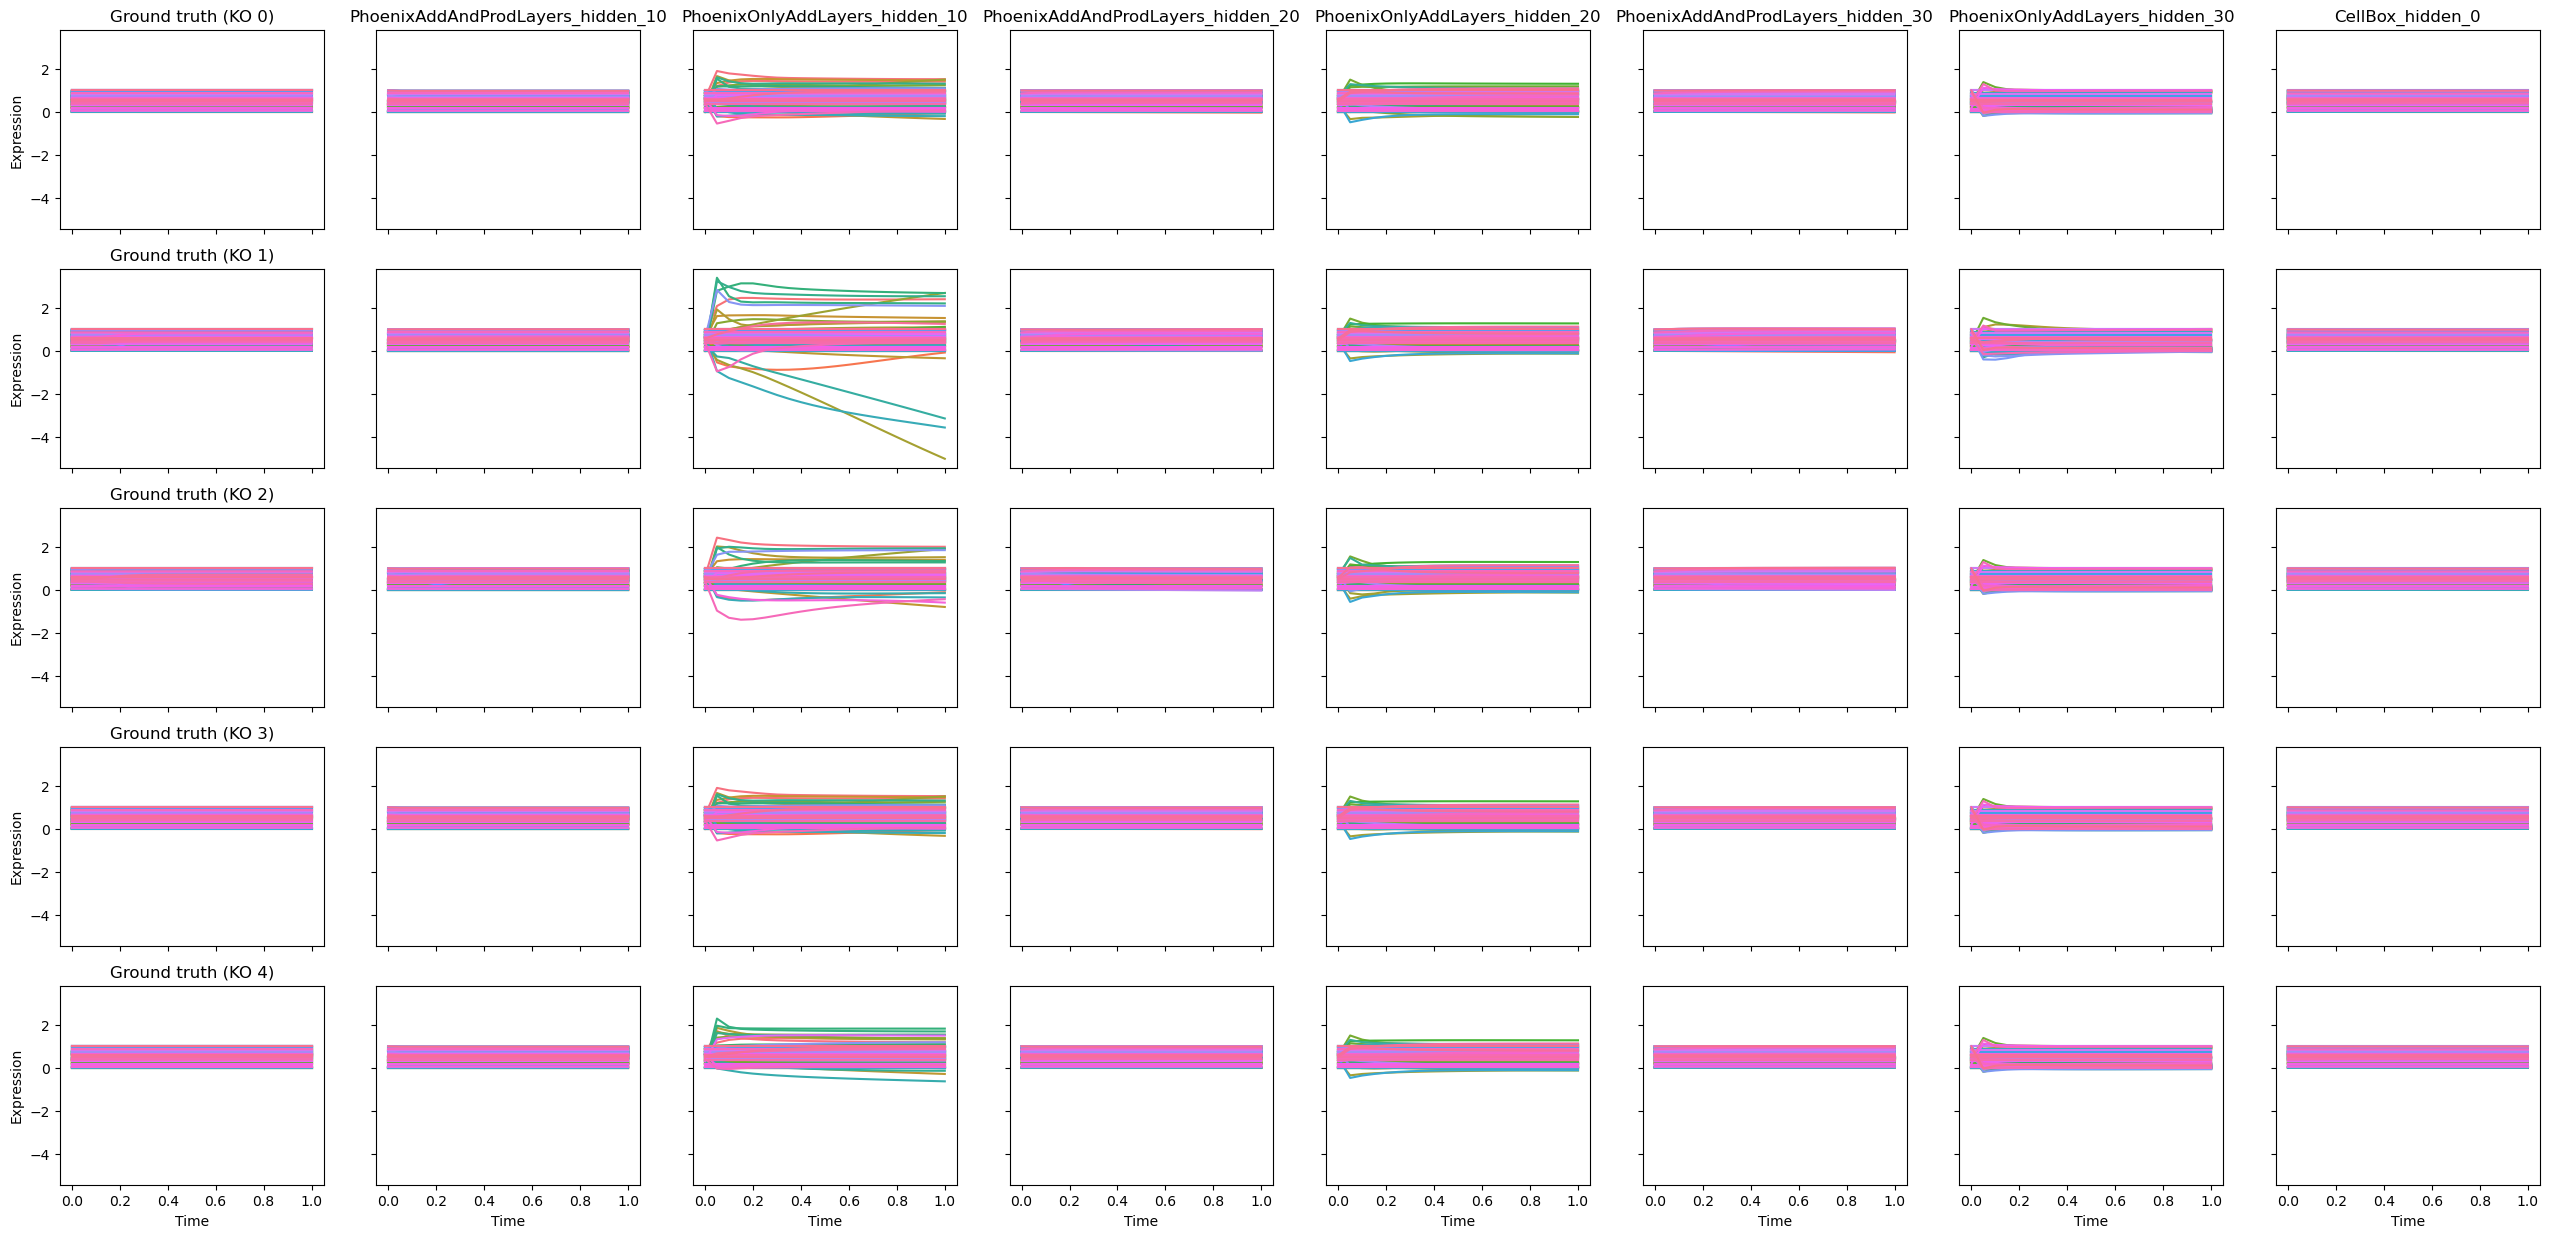

In [19]:
result_list.plot_all_model_fits_into_one_fig(top_n_genes=5)

In [15]:
# Assuming `results` is a list of dicts
df = result_list.summary_dataframe()
df

,final_loss,nr_training_steps,model_path,model_cls,data_path,network_name,nr_genes,nr_modules,sparsity,keep_self_interactions,device,hidden_size,lr,self_activations
0,0.002464,1000,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixAddAndProdLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,100,20,0.05,True,cuda:0,10.0,0.1,NaN
1,0.182168,1000,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixOnlyAddLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,100,20,0.05,True,cuda:0,10.0,0.1,NaN
2,0.001266,1000,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixAddAndProdLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,100,20,0.05,True,cuda:1,20.0,0.1,NaN
3,0.060978,1000,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixOnlyAddLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,100,20,0.05,True,cuda:1,20.0,0.1,NaN
4,0.001217,1000,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixAddAndProdLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,100,20,0.05,True,cuda:0,30.0,0.1,NaN
5,0.212154,1000,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,PhoenixOnlyAddLayers,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,100,20,0.05,True,cuda:0,30.0,0.1,NaN
6,0.001497,1000,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,CellBox,/lustre/BIF/nobackup/noord087/phd/HALCYON/data...,my_network,100,20,0.05,True,cuda:1,NaN,0.1,True


In [16]:
df['model_overall_name'] = df['model_cls'].astype(str) + '_' + df['hidden_size'].astype(str)

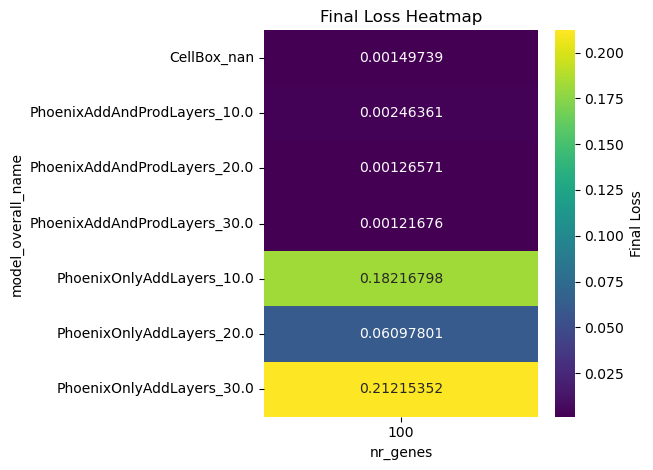

In [17]:
# TODO at some point move this into class methods
# Pivot so genes = columns, modules = rows
heatmap_data = df.pivot_table(
    index="model_overall_name",
    columns="nr_genes",
    values="final_loss",
    # aggfunc="mean"
)

sns.heatmap(
    heatmap_data,
    annot=True,        # write values in the cells
    fmt=".8f",         # number format
    cmap="viridis",    # colour map
    cbar_kws={"label": "Final Loss"}
)
# plt.xlabel("Number of Genes")
# plt.ylabel("Model")
plt.title("Final Loss Heatmap")
plt.tight_layout()
plt.show()

(<Figure size 700x3000 with 20 Axes>,
 array([[<Axes: title={'center': 'Measured (Sample 0)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 0)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 1)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 1)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 2)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 2)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 3)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 3)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 4)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 4)'}, xlabel='Time', ylabel='Expression'>],
        [<Ax

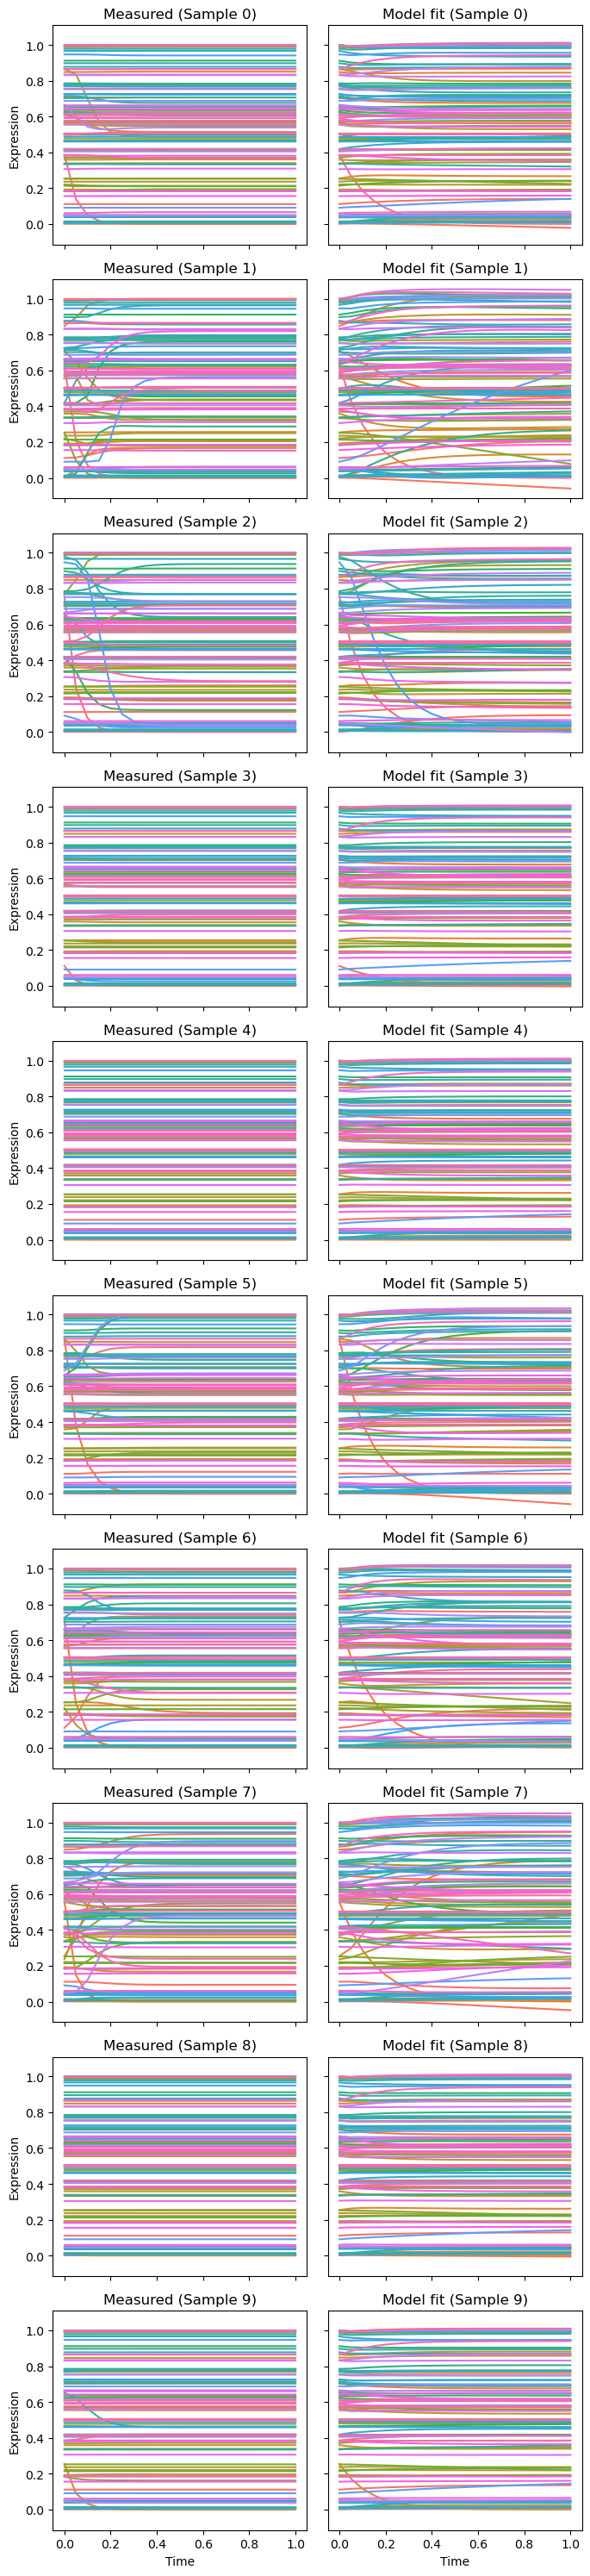

In [23]:
result_list[4].trainer.plot_fit_vs_real(top_n=10, show_legend=False)

(<Figure size 700x3000 with 20 Axes>,
 array([[<Axes: title={'center': 'Measured (Sample 0)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 0)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 1)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 1)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 2)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 2)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 3)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 3)'}, xlabel='Time', ylabel='Expression'>],
        [<Axes: title={'center': 'Measured (Sample 4)'}, xlabel='Time', ylabel='Expression'>,
         <Axes: title={'center': 'Model fit (Sample 4)'}, xlabel='Time', ylabel='Expression'>],
        [<Ax

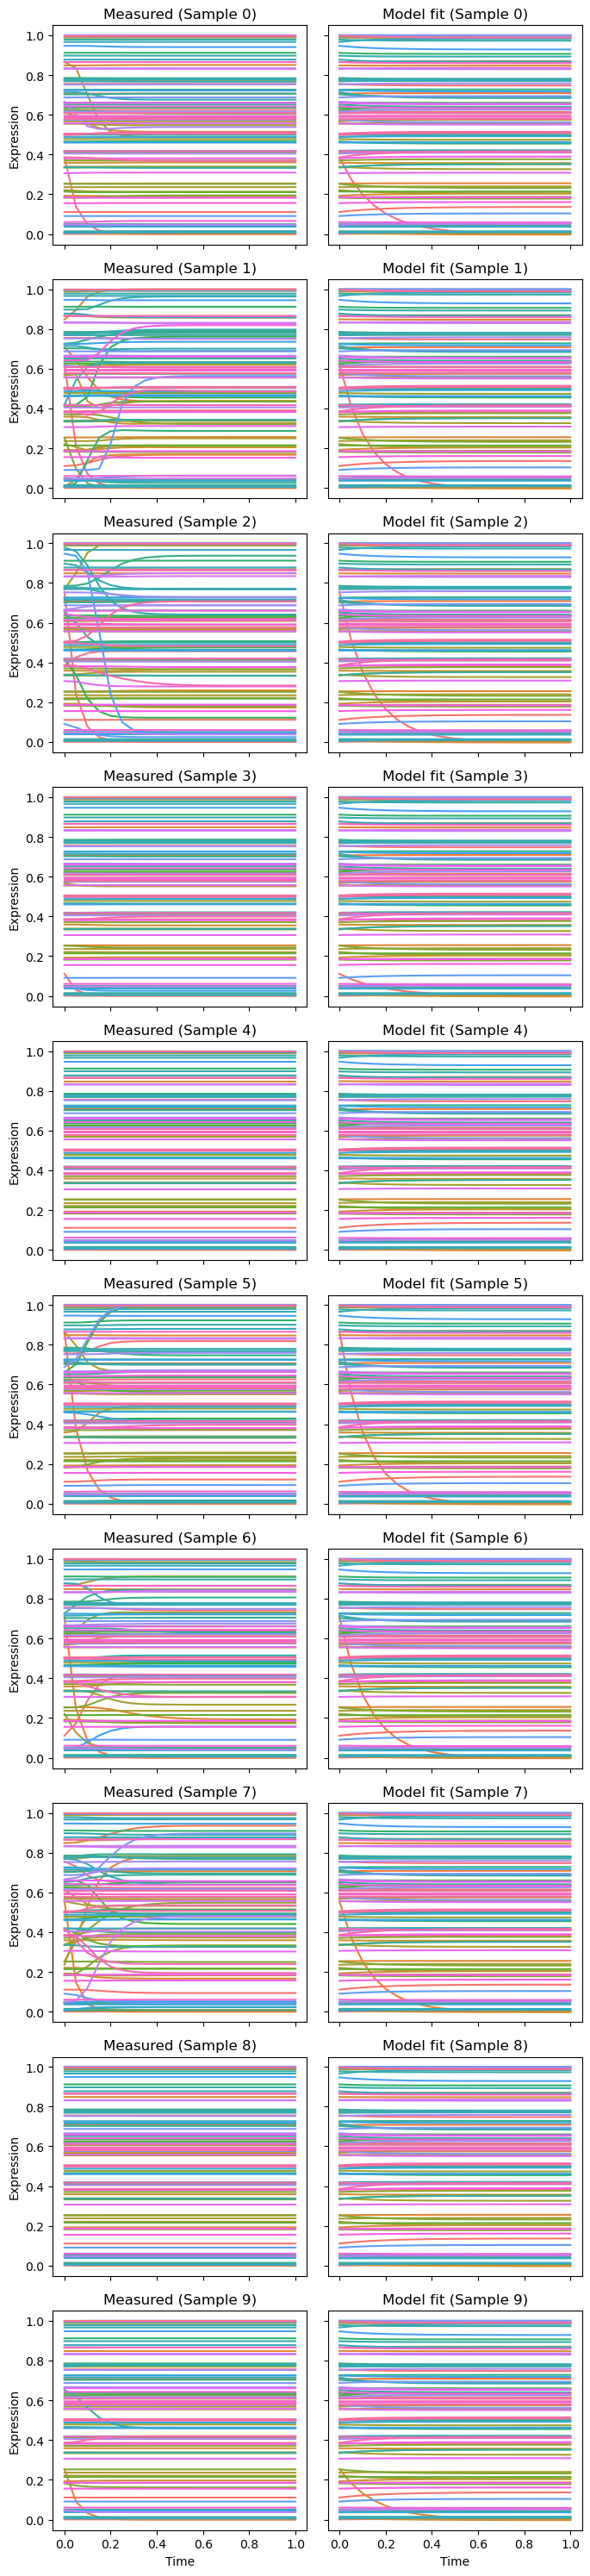

In [25]:
result_list[6].trainer.plot_fit_vs_real(top_n=10, show_legend=False)